<a href="https://colab.research.google.com/github/poornimar2024-sketch/MedExplainAI/blob/main/MM_Kinetics_Seminar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

In [ ]:
def michaelis_menten(S, Vmax, Km):
    return (Vmax * S) / (Km + S)

In [ ]:
def generate_synthetic_data(true_Vmax, true_Km, noise_level=0.3, n_points=20, seed=0):
    rng = np.random.default_rng(seed)
    S = np.linspace(0.1, 10, n_points)
    v_true = michaelis_menten(S, true_Vmax, true_Km)
    noise = rng.normal(0, noise_level, size=S.shape)
    v = v_true + noise
    return S, v

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

In [ ]:
def generate_training_set(n_samples=2000, n_points=20, seed=42):
    rng = np.random.default_rng(seed)
    S = np.linspace(0.1, 10, n_points)  # SAME S grid every single time

    X = []  # features: the v-curve for each sample
    y = []  # labels: [true_Vmax, true_Km] for each sample

    for _ in range(n_samples):
        true_Vmax = rng.uniform(1, 20)
        true_Km = rng.uniform(0.1, 10)
        noise_level = rng.uniform(0.1, 1.0)

        v_true = michaelis_menten(S, true_Vmax, true_Km)
        noise = rng.normal(0, noise_level, size=S.shape)
        v = v_true + noise

        X.append(v)
        y.append([true_Vmax, true_Km])

    return S, np.array(X), np.array(y)

S_train, X, y = generate_training_set()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred = model.predict(X_test)

mae_vmax = mean_absolute_error(y_test[:, 0], y_pred[:, 0])
mae_km = mean_absolute_error(y_test[:, 1], y_pred[:, 1])
print(f"Vmax MAE: {mae_vmax:.3f}")
print(f"Km MAE: {mae_km:.3f}")

Vmax MAE: 0.823
Km MAE: 1.178


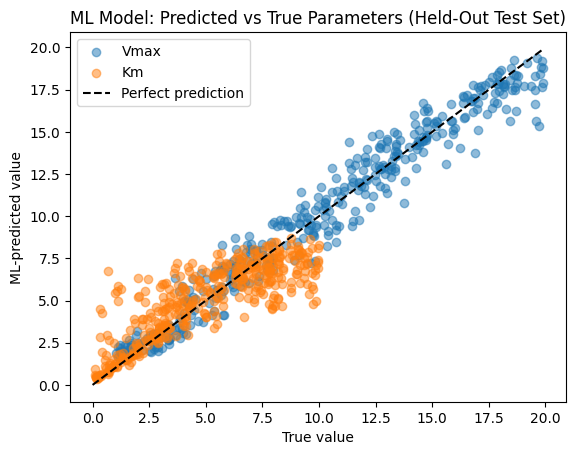

In [ ]:
plt.scatter(y_test[:, 0], y_pred[:, 0], label="Vmax", alpha=0.5)
plt.scatter(y_test[:, 1], y_pred[:, 1], label="Km", alpha=0.5)
max_val = max(y_test.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], 'k--', label="Perfect prediction")
plt.xlabel("True value")
plt.ylabel("ML-predicted value")
plt.legend()
plt.title("ML Model: Predicted vs True Parameters (Held-Out Test Set)")
plt.show()

In [ ]:
from sklearn.metrics import r2_score

def classical_fit(S, v):
    try:
        p, _ = curve_fit(michaelis_menten, S, v,
                         p0=[v.max(), np.median(S)],
                         bounds=([0, 0], [np.inf, np.inf]), maxfev=5000)
        return p
    except RuntimeError:
        return [np.nan, np.nan]

classical_pred = np.array([classical_fit(S_train, v) for v in X_test])
ok = ~np.isnan(classical_pred).any(axis=1)
print(f"Classical fit failed on {(~ok).sum()} / {len(ok)} curves")

for name, i in [("Vmax", 0), ("Km", 1)]:
    print(f"{name}  MAE  ML: {mean_absolute_error(y_test[:, i], y_pred[:, i]):.3f} | "
          f"Classical: {mean_absolute_error(y_test[ok, i], classical_pred[ok, i]):.3f}")
    print(f"{name}  R²   ML: {r2_score(y_test[:, i], y_pred[:, i]):.3f} | "
          f"Classical: {r2_score(y_test[ok, i], classical_pred[ok, i]):.3f}")

# Optional: also compare speed
import time
t = time.time(); model.predict(X_test); t_ml = time.time() - t
t = time.time(); [classical_fit(S_train, v) for v in X_test]; t_cl = time.time() - t
print(f"Time ML: {t_ml:.3f}s | Classical: {t_cl:.3f}s")

Classical fit failed on 0 / 400 curves
Vmax  MAE  ML: 0.823 | Classical: 32.385
Vmax  R²   ML: 0.960 | Classical: -8673.149
Km  MAE  ML: 1.178 | Classical: 188.202
Km  R²   ML: 0.678 | Classical: -1018440.232
Time ML: 0.018s | Classical: 1.436s


Predicted Vmax: 14.267
Predicted Km:   3.114


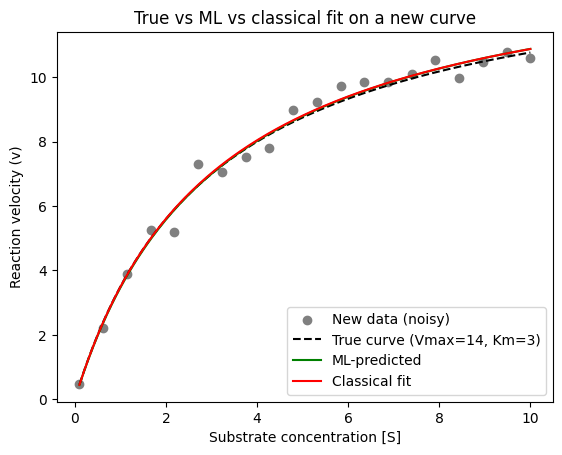

True:      Vmax=14.000, Km=3.000
ML:        Vmax=14.267, Km=3.114
Classical: Vmax=14.220, Km=3.073


In [ ]:
# a "new" curve the model has never seen
S_new, v_new = generate_synthetic_data(true_Vmax=14, true_Km=3, noise_level=0.4, seed=99)

predicted_params = model.predict(v_new.reshape(1, -1))
predicted_Vmax, predicted_Km = predicted_params[0]

print(f"Predicted Vmax: {predicted_Vmax:.3f}")
print(f"Predicted Km:   {predicted_Km:.3f}")

classical_Vmax, classical_Km = classical_fit(S_new, v_new)

S_smooth = np.linspace(0.1, 10, 200)
plt.scatter(S_new, v_new, color="gray", label="New data (noisy)")
plt.plot(S_smooth, michaelis_menten(S_smooth, 14, 3), "k--", label="True curve (Vmax=14, Km=3)")
plt.plot(S_smooth, michaelis_menten(S_smooth, predicted_Vmax, predicted_Km), color="green", label="ML-predicted")
plt.plot(S_smooth, michaelis_menten(S_smooth, classical_Vmax, classical_Km), color="red", label="Classical fit")
plt.xlabel("Substrate concentration [S]")
plt.ylabel("Reaction velocity (v)")
plt.title("True vs ML vs classical fit on a new curve")
plt.legend()
plt.show()

print(f"True:      Vmax=14.000, Km=3.000")
print(f"ML:        Vmax={predicted_Vmax:.3f}, Km={predicted_Km:.3f}")
print(f"Classical: Vmax={classical_Vmax:.3f}, Km={classical_Km:.3f}")

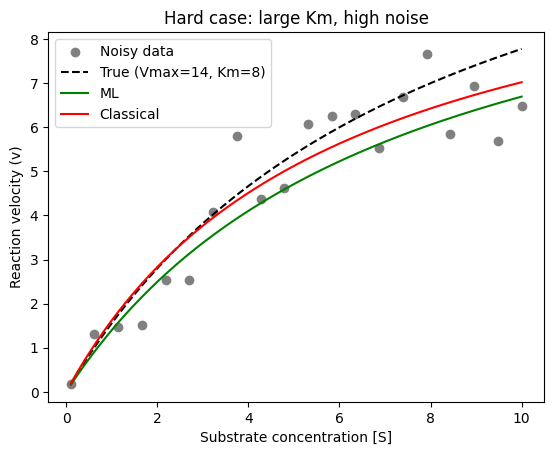

True:      Vmax=14.000, Km=8.000
ML:        Vmax=11.567, Km=7.275
Classical: Vmax=11.157, Km=5.889


In [ ]:
S_hard, v_hard = generate_synthetic_data(true_Vmax=14, true_Km=8, noise_level=1.0, seed=7)

ml_V, ml_K = model.predict(v_hard.reshape(1, -1))[0]
cl_V, cl_K = classical_fit(S_hard, v_hard)

S_smooth = np.linspace(0.1, 10, 200)
plt.scatter(S_hard, v_hard, color="gray", label="Noisy data")
plt.plot(S_smooth, michaelis_menten(S_smooth, 14, 8), "k--", label="True (Vmax=14, Km=8)")
plt.plot(S_smooth, michaelis_menten(S_smooth, ml_V, ml_K), color="green", label="ML")
plt.plot(S_smooth, michaelis_menten(S_smooth, cl_V, cl_K), color="red", label="Classical")
plt.xlabel("Substrate concentration [S]")
plt.ylabel("Reaction velocity (v)")
plt.title("Hard case: large Km, high noise")
plt.legend()
plt.show()

print(f"True:      Vmax=14.000, Km=8.000")
print(f"ML:        Vmax={ml_V:.3f}, Km={ml_K:.3f}")
print(f"Classical: Vmax={cl_V:.3f}, Km={cl_K:.3f}")

In [ ]:
# 1) Median error: robust to a few blow-ups
for name, i in [("Vmax", 0), ("Km", 1)]:
    ml_err = np.abs(y_test[:, i] - y_pred[:, i])
    cl_err = np.abs(y_test[ok, i] - classical_pred[ok, i])
    print(f"{name} median abs error  ML: {np.median(ml_err):.3f} | Classical: {np.median(cl_err):.3f}")

blown = (classical_pred[:, 0] > 100) | (classical_pred[:, 1] > 100)
print(f"Classical gave Vmax or Km > 100 on {blown.sum()} / {len(blown)} curves\n")

# 2) Fairer classical fit, bounded to the training range
def classical_fit_bounded(S, v):
    p, _ = curve_fit(michaelis_menten, S, v, p0=[min(v.max(), 19), 5],
                     bounds=([0, 0], [20, 10]), maxfev=5000)
    return p

cb = np.array([classical_fit_bounded(S_train, v) for v in X_test])
for name, i in [("Vmax", 0), ("Km", 1)]:
    print(f"{name} MAE  ML: {mean_absolute_error(y_test[:, i], y_pred[:, i]):.3f} | "
          f"Classical (bounded): {mean_absolute_error(y_test[:, i], cb[:, i]):.3f}")

Vmax median abs error  ML: 0.653 | Classical: 0.552
Km median abs error  ML: 0.839 | Classical: 0.614
Classical gave Vmax or Km > 100 on 3 / 400 curves

Vmax MAE  ML: 0.823 | Classical (bounded): 0.707
Km MAE  ML: 1.178 | Classical (bounded): 1.148


In [ ]:
#limitation test
S_out, v_out = generate_synthetic_data(true_Vmax=40, true_Km=5, noise_level=0.4, seed=3)
ml_V, ml_K = model.predict(v_out.reshape(1, -1))[0]
cl_V, cl_K = classical_fit(S_out, v_out)

print("True:      Vmax=40.000, Km=5.000")
print(f"ML:        Vmax={ml_V:.3f}, Km={ml_K:.3f}")
print(f"Classical: Vmax={cl_V:.3f}, Km={cl_K:.3f}")

True:      Vmax=40.000, Km=5.000
ML:        Vmax=19.637, Km=1.201
Classical: Vmax=40.784, Km=5.247
